<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# A percentage-full alert is not a free-space ranking

Read a typed SNMP storage table, convert allocation counts to bytes, and compare two capacity questions: which rows cross a utilization threshold, and which have the least absolute free space? Different allocation-unit sizes make the raw counts misleading. A missing denominator must remain unavailable.

**All device responses are synthetic.** A disposable `snmpsim` process serves five invented storage rows over UDP on `127.0.0.1`. The real pinned SNMP worker queries that agent through Haybarn/VGI. No router, server or external device is contacted. This is a fixed fixture, not a live storage observation or growth forecast.

## Choose an alert policy

`ALERT_PERCENT` is a percentage from **1 to 99**, default **80**. The focused experiment lowers it to **70**, changing only the classification policy. Allocation counts and the local agent stay identical. Restart and run all after editing.

In [1]:
ALERT_PERCENT = 80

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from local_agent import LocalAgent
from notebook_support import finish, theme

assert isinstance(ALERT_PERCENT, (int, float)) and not isinstance(ALERT_PERCENT, bool) and 1 <= ALERT_PERCENT <= 99
manifest = json.loads(Path("fixtures/provenance.json").read_text())
assert hashlib.sha256(Path("fixtures/public.snmprec").read_bytes()).hexdigest() == manifest["sha256"]
theme()
agent = LocalAgent()
AGENT = agent.host
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-snmp/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-snmp/notebooks/pyproject.toml.

## Start the published worker and ask for its table schema

The literal launch command fetches a pinned public Git revision with a compatible SDK and pysnmp version. It does not use this checkout or build a local worker. `DESCRIBE` resolves the HOST-RESOURCES-MIB table offline; the following retrieval performs actual SNMP requests to the synthetic loopback agent. `public` is this fixture’s deliberately public community name, not a device credential.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'snmp' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --with vgi-rpc==0.53.1 --with pysnmp==7.1.32 --with cryptography==50.0.2 --from git+https://github.com/Query-farm/vgi-snmp@36ca434ba473186270f38f96cb0a17338187a598 vgi-snmp-worker');
DESCRIBE SELECT * FROM snmp.main.snmp_table('{{ AGENT }}','hrStorageTable',version:='2c',community:='public');

,column_name,column_type,null,key,default,extra
0,hrStorageType,VARCHAR,YES,None,None,None
1,hrStorageDescr,VARCHAR,YES,None,None,None
2,hrStorageAllocationUnits,BIGINT,YES,None,None,None
3,hrStorageSize,BIGINT,YES,None,None,None
4,hrStorageUsed,BIGINT,YES,None,None,None
5,hrStorageAllocationFailures,BIGINT,YES,None,None,None


In [4]:
%%sql
CREATE TABLE identity AS SELECT * FROM snmp.main.snmp_get('{{ AGENT }}','sysName.0','sysUpTime.0',
 version:='2c',community:='public',timeout:=2,retries:=0);
CREATE TABLE storage_raw AS SELECT _index,hrStorageIndex,hrStorageDescr,hrStorageAllocationUnits,hrStorageSize,hrStorageUsed
FROM snmp.main.snmp_table('{{ AGENT }}','hrStorageTable',version:='2c',community:='public',timeout:=2,retries:=0);
CREATE TABLE policy AS SELECT {{ ALERT_PERCENT }}::DOUBLE AS alert_percent;

,Count


In [5]:
%%sql device <<
SELECT max(CASE WHEN object='sysName' THEN value END) AS agent_name,
 max(CASE WHEN object='sysUpTime' THEN value_int/8640000.0 END) AS uptime_days FROM identity;

In [6]:
%%sql inventory <<
SELECT hrStorageIndex AS storage_index,hrStorageDescr AS storage,
 hrStorageAllocationUnits AS bytes_per_unit,hrStorageSize AS size_units,hrStorageUsed AS used_units
FROM storage_raw ORDER BY hrStorageIndex;

In [7]:
display(device)
display(inventory)

,agent_name,uptime_days
0,invented-storage-host,1.0


,storage_index,storage,bytes_per_unit,size_units,used_units
0,1,Memory,8192,2097152,1572864
1,7,Root volume,4096,33554432,29360128
2,31,Data volume,65536,33554432,16777216
3,42,Backup volume,4096,134217728,125829120
4,99,Unavailable size,4096,0,0


## Convert counts before comparing capacities

The MIB reports both size and used space in **allocation units**, whose byte size is separate and can vary by row. SQL multiplies in `HUGEINT` before converting to **GiB = 2³⁰ bytes**. Utilization is `100 × used / size` only when the denominator and counts are valid. Zero size is not evidence of zero utilization; that row is explicitly unavailable.

Each worker call was materialized once before display, so the plots reuse one fixed set of returned values. Real SNMP reads can span packets and are not atomic snapshots. Memory and disk rows are shown individually; their capacities are not added into a host-wide storage total.

In [8]:
%%sql
CREATE TABLE storage AS
WITH typed AS (
 SELECT hrStorageIndex AS storage_index,hrStorageDescr AS storage,
 hrStorageAllocationUnits AS bytes_per_unit,hrStorageSize AS size_units,hrStorageUsed AS used_units,
 hrStorageAllocationUnits>0 AND hrStorageSize>0 AND hrStorageUsed>=0 AND hrStorageUsed<=hrStorageSize AS usable
 FROM storage_raw
), bytes AS (
 SELECT *,CASE WHEN usable THEN bytes_per_unit::HUGEINT*size_units END AS capacity_bytes,
 CASE WHEN usable THEN bytes_per_unit::HUGEINT*used_units END AS used_bytes FROM typed
)
SELECT *,capacity_bytes-used_bytes AS free_bytes,
 capacity_bytes/1073741824.0 AS capacity_gib,used_bytes/1073741824.0 AS used_gib,
 (capacity_bytes-used_bytes)/1073741824.0 AS free_gib,
 CASE WHEN usable THEN 100.0*used_units/size_units END AS used_percent,
 CASE WHEN NOT usable THEN 'unavailable'
 WHEN 100.0*used_units/size_units >= alert_percent THEN 'at or above threshold'
 ELSE 'below threshold' END AS classification
FROM bytes CROSS JOIN policy;

,Count


In [9]:
%%sql capacity <<
SELECT * FROM storage ORDER BY used_percent DESC NULLS LAST,storage_index;

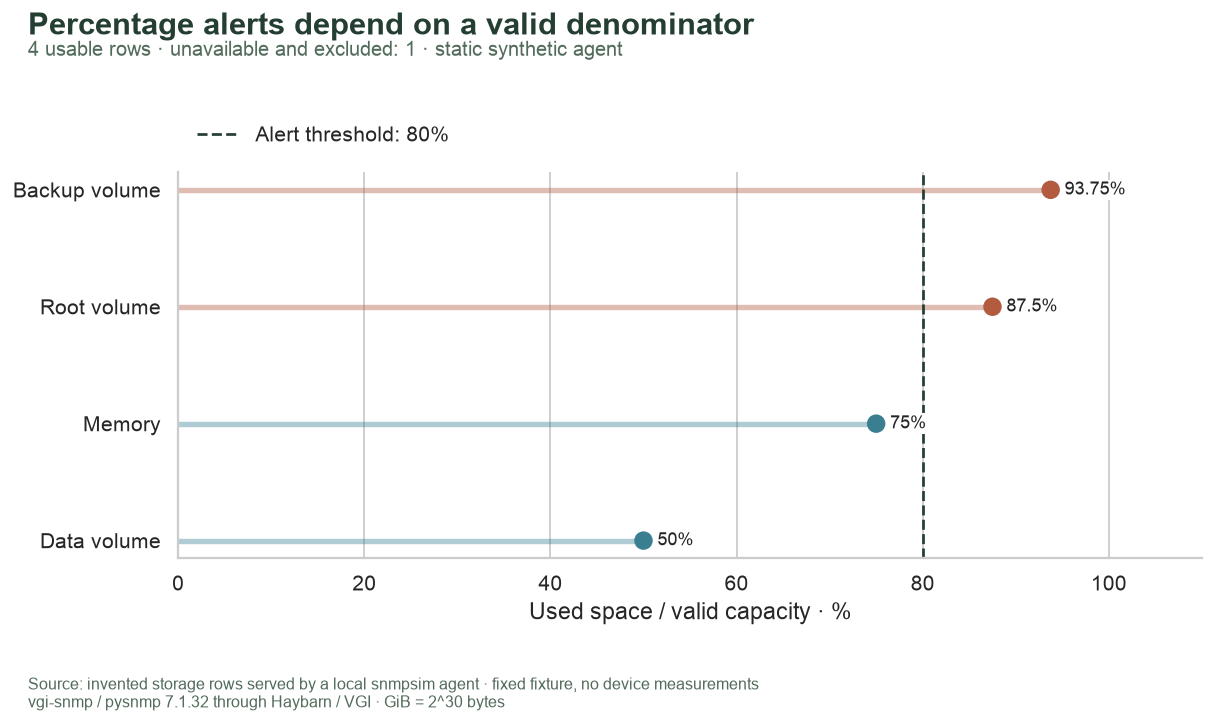

In [10]:
known = capacity.loc[capacity.usable].copy()
missing = capacity.loc[~capacity.usable].copy()
fig, ax = plt.subplots(figsize=(10.5, 5.6))
y = np.arange(len(known))
colors = ["#b25b3f" if v >= ALERT_PERCENT else "#397f91" for v in known.used_percent]
ax.hlines(y, 0, known.used_percent, color=colors, alpha=0.4, linewidth=3)
ax.scatter(known.used_percent, y, c=colors, s=85, zorder=3)
for i, row in enumerate(known.itertuples()):
    ax.text(
        float(row.used_percent) + 1.5,
        i,
        f"{row.used_percent:g}%",
        va="center",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1},
    )
ax.axvline(ALERT_PERCENT, color="#243e32", linestyle="--", linewidth=1.5, label=f"Alert threshold: {ALERT_PERCENT:g}%")
ax.set(yticks=y, yticklabels=known.storage, xlim=(0, 110), xlabel="Used space / valid capacity · %")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), frameon=False)
finish(
    fig,
    f"utilization-{ALERT_PERCENT}",
    "Percentage alerts depend on a valid denominator",
    f"{len(known)} usable rows · unavailable and excluded: {len(missing)} · static synthetic agent",
)

## Compare absolute free headroom

An alert threshold is a policy, not a ranking by remaining bytes. Sort the same returned rows by free GiB to see how a smaller memory pool can have less headroom even below the utilization threshold. The horizontal axis is **logarithmic** to make the different orders of magnitude readable; labels give exact values. This fixture has positive free space on every usable row. A zero-free row would be labeled separately rather than forced onto a log scale.

In [11]:
%%sql headroom <<
SELECT storage,free_gib,capacity_gib,used_percent,classification FROM storage
WHERE usable ORDER BY free_gib,storage;

,storage,free_gib,capacity_gib,used_percent,classification
0,Memory,4.0,16.0,75.00,below threshold
1,Root volume,16.0,128.0,87.50,at or above threshold
2,Backup volume,32.0,512.0,93.75,at or above threshold
3,Data volume,1024.0,2048.0,50.00,below threshold


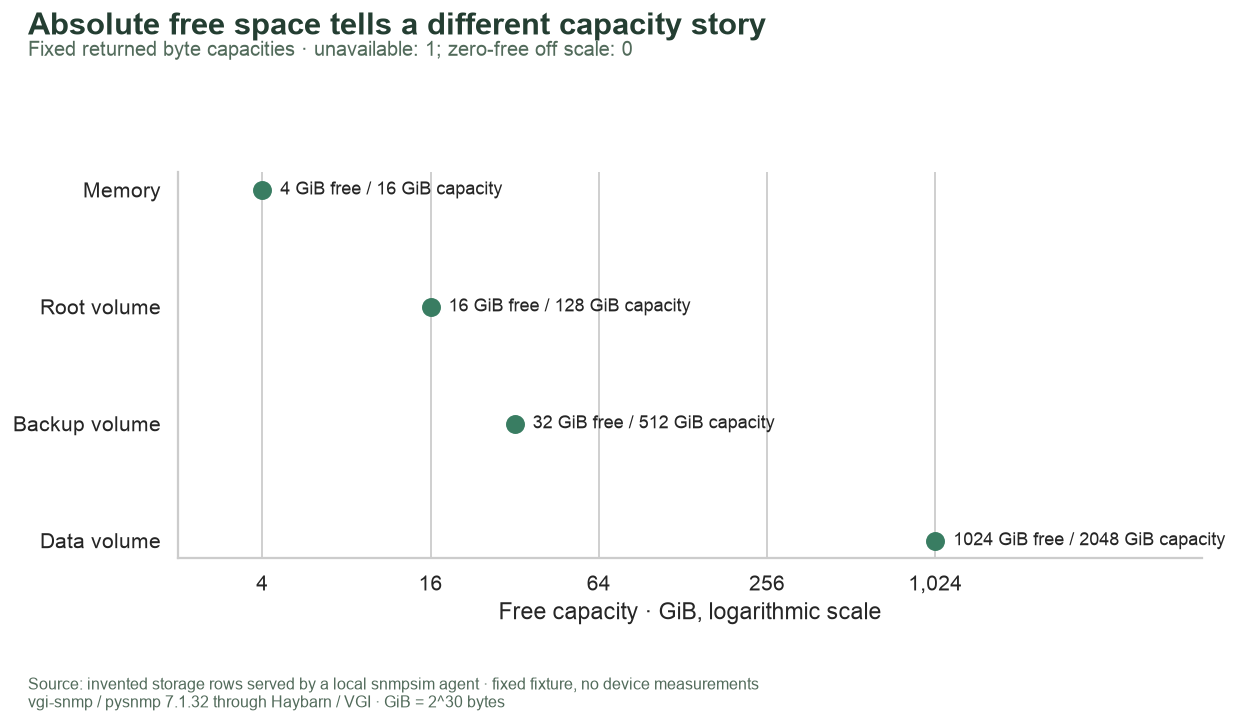

In [12]:
display(headroom)
fig, ax = plt.subplots(figsize=(10.5, 5.6))
positive = headroom.loc[headroom.free_gib > 0]
y = np.arange(len(positive))
ax.scatter(positive.free_gib, y, color="#397d62", s=90, zorder=3)
for i, row in enumerate(positive.itertuples()):
    ax.annotate(
        f"{row.free_gib:g} GiB free / {row.capacity_gib:g} GiB capacity",
        (row.free_gib, i),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
    )
ax.set_xscale("log")
ax.set_xticks([4, 16, 64, 256, 1024], ["4", "16", "64", "256", "1,024"])
ax.set(
    yticks=y,
    yticklabels=positive.storage,
    xlim=(max(float(positive.free_gib.min()) / 2, 0.01), float(positive.free_gib.max()) * 9),
    xlabel="Free capacity · GiB, logarithmic scale",
)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
zero = headroom.loc[headroom.free_gib == 0]
finish(
    fig,
    "free-headroom",
    "Absolute free space tells a different capacity story",
    f"Fixed returned byte capacities · unavailable: {len(missing)}; zero-free off scale: {len(zero)}",
)

In [13]:
alerts = known.loc[known.used_percent >= ALERT_PERCENT]
least = headroom.iloc[0]
most = known.iloc[0]
uptime = device.iloc[0].uptime_days
display(
    Markdown(
        f"At threshold **{ALERT_PERCENT:g}%**, **{len(alerts)} of {len(known)} usable rows** enter the alert queue: "
        + (", ".join(alerts.storage) + "." if len(alerts) else "none.")
        + f" **{least.storage}** has the least free capacity (**{least.free_gib:g} GiB**), while "
        f"**{most.storage}** has the highest utilization (**{most.used_percent:g}%**). "
        f"Unavailable rows (**{len(missing)}**) remain outside both rankings. "
        f"The fixture's sysUpTime converts to **{uptime:g} {'day' if uptime == 1 else 'days'}**; "
        "it is invented agent uptime, not a disk age, sample interval or basis for forecasting when space will run out."
    )
)

At threshold **80%**, **2 of 4 usable rows** enter the alert queue: Backup volume, Root volume. **Memory** has the least free capacity (**4 GiB**), while **Backup volume** has the highest utilization (**93.75%**). Unavailable rows (**1**) remain outside both rankings. The fixture's sysUpTime converts to **1 day**; it is invented agent uptime, not a disk age, sample interval or basis for forecasting when space will run out.

## Check identities, units and unavailable values

The checks reconcile exact byte arithmetic, enforce one MIB row per index, and keep invalid denominators outside the alert count. No check requires a particular threshold to produce a preferred alert count.

In [14]:
%%sql checks <<
SELECT 'raw table indices are unique' AS check_name,
 (SELECT count(*)=count(DISTINCT _index) AND count(*)=count(DISTINCT hrStorageIndex) FROM storage_raw) AS passed
UNION ALL SELECT 'MIB suffix agrees with typed storage index',
 (SELECT bool_and(_index=hrStorageIndex::VARCHAR) FROM storage_raw)
UNION ALL SELECT 'all rows survive transformation',
 (SELECT count(*)=(SELECT count(*) FROM storage_raw) FROM storage)
UNION ALL SELECT 'unavailable values stay null',
 (SELECT bool_and(capacity_bytes IS NULL AND used_bytes IS NULL AND free_bytes IS NULL
 AND used_percent IS NULL AND classification='unavailable') FROM storage WHERE NOT usable)
UNION ALL SELECT 'usable bytes reconcile exactly',
 (SELECT bool_and(used_bytes+free_bytes=capacity_bytes) FROM storage WHERE usable)
UNION ALL SELECT 'capacity uses each row allocation size',
 (SELECT bool_and(capacity_bytes=bytes_per_unit::HUGEINT*size_units) FROM storage WHERE usable)
UNION ALL SELECT 'GiB conversion agrees with bytes',
 (SELECT bool_and(abs(capacity_gib*1073741824-capacity_bytes)<0.5
 AND abs(free_gib*1073741824-free_bytes)<0.5) FROM storage WHERE usable)
UNION ALL SELECT 'utilization stays within physical bounds',
 (SELECT bool_and(used_percent BETWEEN 0 AND 100 AND free_bytes>=0) FROM storage WHERE usable)
UNION ALL SELECT 'byte and allocation utilization agree',
 (SELECT bool_and(abs(used_percent-100.0*used_bytes/capacity_bytes)<1e-10) FROM storage WHERE usable)
UNION ALL SELECT 'alert classification agrees with selected policy',
 (SELECT bool_and((classification='at or above threshold')=(used_percent>=alert_percent)) FROM storage WHERE usable)
UNION ALL SELECT 'GET preserves requested instance identity',
 (SELECT count(*)=2 AND count(DISTINCT object)=2 AND bool_and(instance='0') FROM identity)
UNION ALL SELECT 'uptime has the expected SNMP type and valid integer',
 (SELECT type='TimeTicks' AND value_int>=0 FROM identity WHERE object='sysUpTime');

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
assert len(capacity) == manifest["rows"]
display(Markdown(f"**{len(checks)} SQL checks passed**, plus fixture hash and row-count checks."))

,check_name,passed
0,raw table indices are unique,True
1,MIB suffix agrees with typed storage index,True
2,all rows survive transformation,True
3,unavailable values stay null,True
4,usable bytes reconcile exactly,True
5,capacity uses each row allocation size,True
6,GiB conversion agrees with bytes,True
7,utilization stays within physical bounds,True
8,byte and allocation utilization agree,True
9,alert classification agrees with selected policy,True


**12 SQL checks passed**, plus fixture hash and row-count checks.

## Focused experiment: lower the threshold

Change only **`ALERT_PERCENT` from 80 to 70**, restart and run all. Predict that rows may enter the alert queue, but no row leaves it. Compare the percentage chart and queue with the saved default, then verify that the absolute free-space plot and returned capacities are unchanged.

This changes a policy over the same fixed data; it does not simulate growth, reclaim space or establish a safe operating threshold. Restore **80** for the baseline. The README command writes the experiment to a separate destination.

In [16]:
connection.close()
agent.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>